<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/recall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔍 召回率 (Recall / Sensitivity)

> **一句話記住**：召回率在問 —— **真正是的那些，模型抓到了幾個？**
> 召回率高 = 模型**不漏抓**、很少「漏報」。

📚 [回到評估指標總覽](./README.md)

## 🎯 學完這份筆記本，你會…
- 手算與用 `sklearn` 算出召回率
- 判斷什麼情境「**漏報 (FN) 很危險**」，需要重視召回率
- 理解**精確率與召回率的拉鋸**

---

## 🎣 生活比喻：撒網捕魚

湖裡有 5 條魚，你撒一網撈到 4 條（還順便撈到 1 隻破鞋子）。

> 召回率 = 撈到的魚 ÷ 湖裡全部的魚 = 4 ÷ 5 = **80%**

被漏掉的那條魚就是 **FN（假負例）**。破鞋子 (FP) 召回率不管，那是精確率的事。

## 📐 公式

$$\text{Recall} = \frac{TP}{TP + FN} = \frac{\text{抓到的}}{\text{實際上全部該抓的}}$$

**白話讀法**：分母是「實際上真的是的全部」，只看混淆矩陣的**「實際為是」那一列**。

---
### 【步驟 0】環境準備：載入套件與中文字型

> 這一格只要**按執行**就好，不用看懂。它會幫你安裝中文字型，讓圖表上的中文不會變成 □□□。

In [1]:
# 【步驟 0】載入套件與設定中文字型（Colab / Mac / Windows 通用）
import os, glob, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mplfonts
except ImportError:  # Colab 第一次執行時自動安裝
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mplfonts"])
    import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")

# 統一圖表風格：去掉上、右邊框，讓畫面更乾淨
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "figure.dpi": 100,
})
BLUE, GREEN, RED, ORANGE, PURPLE, GRAY = "#3182ce", "#38a169", "#e53e3e", "#dd6b20", "#805ad5", "#a0aec0"

print("✅ 套件與中文字型載入完成！")

✅ 套件與中文字型載入完成！


---
### 【步驟 1】準備資料：癌症篩檢 10 人，`1` = 罹癌、`0` = 健康

In [2]:
# 學生可以透過 prompt: "定義癌症篩檢情境的 y_true 與 y_pred，並列出所有「實際罹癌」的病人與模型的判斷"
y_true = [1, 0, 1, 0, 1, 0, 0, 1, 0, 1]  # 實際：1=罹癌、0=健康
y_pred = [1, 0, 1, 1, 1, 0, 0, 0, 0, 1]  # 模型的預測

df = pd.DataFrame({
    "病人": [f"病人{i+1}" for i in range(10)],
    "實際": ["罹癌" if t else "健康" for t in y_true],
    "預測": ["罹癌" if p else "健康" for p in y_pred],
})
df["抓到了嗎"] = ["✅ 抓到" if p == 1 else "❌ 漏診" for p in y_pred]
print("🩺 實際罹癌的病人：")
display(df[df["實際"] == "罹癌"])

🩺 實際罹癌的病人：


,病人,實際,預測,抓到了嗎
0,病人1,罹癌,罹癌,✅ 抓到
2,病人3,罹癌,罹癌,✅ 抓到
4,病人5,罹癌,罹癌,✅ 抓到
7,病人8,罹癌,健康,❌ 漏診
9,病人10,罹癌,罹癌,✅ 抓到


#### 👀 看懂結果
5 位罹癌病人中，**病人 8 被漏診**（模型說健康）→ 這就是 FN，在醫療上是最危險的錯誤。

---
### 【步驟 2】手算召回率，再用 sklearn 驗證

In [3]:
# 學生可以透過 prompt: "計算 TP 與 FN，依公式 TP/(TP+FN) 手算召回率（避免除以零），並用 sklearn 的 recall_score 驗證"
from sklearn.metrics import recall_score

TP = sum((t == 1 and p == 1) for t, p in zip(y_true, y_pred))
FN = sum((t == 1 and p == 0) for t, p in zip(y_true, y_pred))
FP = sum((t == 0 and p == 1) for t, p in zip(y_true, y_pred))
TN = sum((t == 0 and p == 0) for t, p in zip(y_true, y_pred))

recall = TP / (TP + FN) if (TP + FN) > 0 else 0

print(f"實際罹癌：{TP + FN} 人（TP={TP} + FN={FN}）")
print(f"模型抓到：{TP} 人")
print(f"📝 手算召回率      ：{recall:.2f}")
print(f"🤖 sklearn 召回率 ：{recall_score(y_true, y_pred):.2f}")

實際罹癌：5 人（TP=4 + FN=1）
模型抓到：4 人
📝 手算召回率      ：0.80
🤖 sklearn 召回率 ：0.80


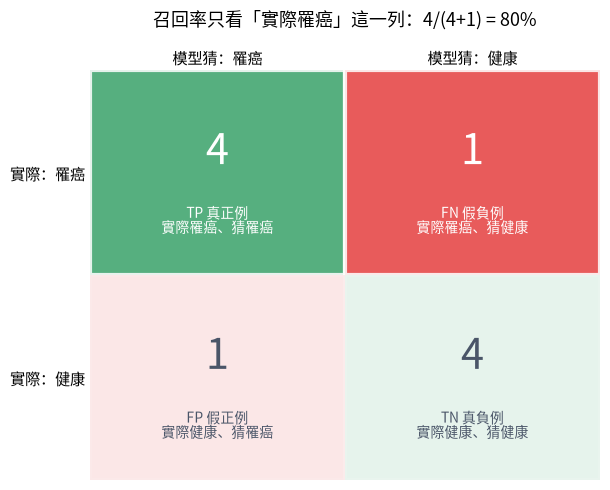

In [4]:
# 🛠️ 畫圖小工具：畫出「好讀版」混淆矩陣（不用背，會用就好）
def draw_confusion(TP, FN, FP, TN, pos="正類", neg="負類", highlight=None, title="混淆矩陣"):
    """highlight 可傳入要強調的格子，例如 ["TP", "FP"]；其他格子會變淡。"""
    cells = {
        "TP": (0, 0, TP, f"TP 真正例\n實際{pos}、猜{pos}", GREEN),
        "FN": (0, 1, FN, f"FN 假負例\n實際{pos}、猜{neg}", RED),
        "FP": (1, 0, FP, f"FP 假正例\n實際{neg}、猜{pos}", RED),
        "TN": (1, 1, TN, f"TN 真負例\n實際{neg}、猜{neg}", GREEN),
    }
    fig, ax = plt.subplots(figsize=(6.2, 5))
    for key, (r, c, n, label, color) in cells.items():
        alpha = 0.85 if (highlight is None or key in highlight) else 0.12
        ax.add_patch(plt.Rectangle((c, 1 - r), 1, 1, color=color, alpha=alpha, ec="white", lw=3))
        txt_color = "white" if alpha > 0.5 else "#4a5568"
        ax.text(c + 0.5, 1.62 - r, str(n), ha="center", va="center", fontsize=30, color=txt_color)
        ax.text(c + 0.5, 1.27 - r, label, ha="center", va="center", fontsize=10, color=txt_color)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2)
    ax.set_xticks([0.5, 1.5]); ax.set_xticklabels([f"模型猜：{pos}", f"模型猜：{neg}"], fontsize=11)
    ax.set_yticks([1.5, 0.5]); ax.set_yticklabels([f"實際：{pos}", f"實際：{neg}"], fontsize=11)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title, pad=32)
    plt.tight_layout()
    plt.show()

draw_confusion(TP, FN, FP, TN, pos="罹癌", neg="健康", highlight=["TP", "FN"],
               title=f"召回率只看「實際罹癌」這一列：{TP}/({TP}+{FN}) = {recall:.0%}")

---
### 【步驟 3】實驗：精確率與召回率的「拉鋸戰」

如果醫院為了**不漏掉任何病人**，讓模型「**所有人都說有病**」呢？

,召回率,精確率
模型,,
原本的模型,0.8,0.8
全部說罹癌,1.0,0.5


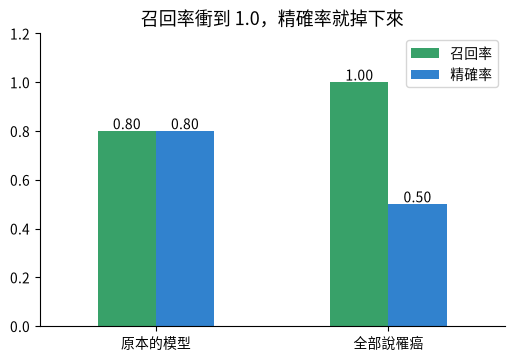

In [5]:
# 學生可以透過 prompt: "比較原本模型與「全部猜罹癌」模型的精確率和召回率，並以分組長條圖呈現"
from sklearn.metrics import precision_score

y_pred_all = [1] * 10   # 全部說「罹癌」

models = {"原本的模型": y_pred, "全部說罹癌": y_pred_all}
rows = []
for name, pred in models.items():
    rows.append({"模型": name,
                 "召回率": recall_score(y_true, pred),
                 "精確率": precision_score(y_true, pred)})
result = pd.DataFrame(rows).set_index("模型")
display(result.round(2))

ax = result.plot(kind="bar", color=[GREEN, BLUE], figsize=(6, 3.8), rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
ax.set_ylim(0, 1.2)
ax.set_title("召回率衝到 1.0，精確率就掉下來")
ax.set_xlabel("")
plt.show()

#### 👀 看懂結果
「全部說罹癌」召回率是完美的 **1.00**（一個都沒漏），但精確率掉到 **0.50**（一半健康的人被嚇到、要做昂貴的複檢）。

> 🔄 **精確率 ↔ 召回率常常是此消彼長**：想抓得更完整（召回率↑），就容易誤報更多（精確率↓）。
> 想同時兼顧兩者，就要用下一份的 👉 [F1 分數](./f1_score.ipynb)。

---
## 🧭 什麼時候要特別重視召回率？

當「**漏報 (FN) 的代價很高**」時：

| 情境 | 漏報 (FN) 的後果 |
| :--- | :--- |
| 🩺 癌症 / 傳染病篩檢 | 病人錯過治療黃金期 |
| 💳 盜刷偵測 | 盜刷沒被攔下，造成損失 |
| 🏭 產線瑕疵品檢測 | 瑕疵品流到客戶手上 |

---
## ⚠️ 常見誤區

| 誤區 | 正確觀念 |
| :--- | :--- |
| 召回率 100% 就是完美模型 | 「全部猜是」就能 100%，要同時看精確率。 |
| 召回率和精確率分母一樣 | 召回率分母 = **實際是的**；精確率分母 = **模型說是的**。 |

> 🧠 **記憶法**：**精確率**看「**模型的嘴**」說的準不準；**召回率**看「**真相**」被找回多少。

---
## ✍️ 隨堂練習

**練習**：工廠有 50 個瑕疵品，模型抓到 40 個，還誤抓了 10 個良品。召回率和精確率各是多少？

<details>
<summary>💡 點我看答案</summary>

TP = 40、FN = 50 − 40 = 10、FP = 10
- 召回率 = 40 ÷ 50 = **0.80**
- 精確率 = 40 ÷ (40 + 10) = **0.80**

</details>

---
## 📝 重點回顧

| 重點 | 內容 |
| :--- | :--- |
| 問題 | 真正是的，抓到了幾個？ |
| 公式 | TP ÷ (TP + FN) |
| sklearn | `recall_score(y_true, y_pred)` |
| 別名 | 敏感度 (Sensitivity)、真正例率 (TPR) |
| 重視時機 | **漏報 (FN) 代價高**：疾病篩檢、盜刷、瑕疵品 |
| 下一步 | 👉 [F1 分數](./f1_score.ipynb) |

## 🤖 問問 AI
> 「請舉 3 個『寧可錯殺一百，不可放過一個』的機器學習應用，並說明為什麼它們要優先看召回率。」